# DeepLense Common Test I: data exploration and train/validation split

**Task (ML4SCI GSoC test):** classify simulated strong-lensing images into 3 classes and report ROC curves and AUC.
This notebook only **looks at and checks the data**, then **fixes the split** that every later notebook uses.

| Folder | Class | What it means physically |
|---|---|---|
| `no` | no substructure | a smooth dark-matter halo bends the light |
| `sphere` | subhalo (CDM) | small point-like dark-matter clumps add slight distortions |
| `vort` | vortex | string-like (vortex) dark-matter structures add slight distortions |

**Split used in this project.** The data comes as `train/` (30,000 images) and `val/` (7,500 images). The test asks for a 90:10
train/validation split. I split `train/` 90:10 (stratified, seed 42): the 90 % trains the model, the 10 % chooses the best
epoch and hyper-parameters. The provided `val/` folder is never used for any choice and is only used once, at the end,
to report the final ROC/AUC. In code it is called `test`, so the two meanings of "validation" never get mixed up.

In [1]:
import hashlib, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

SEED = 42
ROOT = Path("~/gsoc/eval-tests/ml4sci-deeplense").expanduser()
RAW  = ROOT / "data/raw/common/dataset"
PROC = ROOT / "data/processed/common"
FIG  = ROOT / "report/figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

CLASSES = ["no", "sphere", "vort"]                       # folder names; label = position in this list
NAMES   = {"no": "no substructure", "sphere": "subhalo (CDM)", "vort": "vortex"}
IMG_SHAPE = (1, 150, 150)

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower"})
print("numpy", np.__version__, "| data folder exists:", RAW.is_dir())

numpy 2.4.6 | data folder exists: True


## 1. List the files and count them
Files are named `1.npy … 10000.npy`. I sort them by their **number**, not as text (text order would put `10.npy` before `2.npy`),
so the order is the same on every machine. I also make sure the folders contain nothing except `.npy` files (apart from macOS
`.DS_Store` folder-metadata files that came inside the zip).

In [2]:
def list_split(split):
    # Return (paths, labels) for one split, sorted by class and then by file number.
    paths, labels = [], []
    for label, cls in enumerate(CLASSES):
        files = sorted((RAW / split / cls).glob("*.npy"), key=lambda p: int(p.stem))
        paths += files
        labels += [label] * len(files)
    return paths, np.array(labels, dtype=np.int64)

train_paths, y_trainfull = list_split("train")
test_paths,  y_test      = list_split("val")            # provided val/ folder = held-out test set

non_npy = [p for p in RAW.rglob("*") if p.is_file() and p.suffix != ".npy"]
mac_junk = [p for p in non_npy if p.name == ".DS_Store"]          # macOS folder metadata from the zip, safe to ignore
other = [p for p in non_npy if p not in mac_junk]
print(f"ignored {len(mac_junk)} macOS .DS_Store files | other non-.npy files: {other}")

counts = pd.DataFrame(
    {"train/": np.bincount(y_trainfull, minlength=3), "val/ (held-out test)": np.bincount(y_test, minlength=3)},
    index=[f"{c} = {NAMES[c]}" for c in CLASSES],
)
counts.loc["total"] = counts.sum()
display(counts)
assert counts.loc["total"].tolist() == [30000, 7500] and not other

ignored 3 macOS .DS_Store files | other non-.npy files: []


,train/,val/ (held-out test)
no = no substructure,10000,2500
sphere = subhalo (CDM),10000,2500
vort = vortex,10000,2500
total,30000,7500


## 2. Look at one file

In [3]:
x = np.load(train_paths[0], allow_pickle=False)
print("file :", train_paths[0].relative_to(RAW))
print("dtype:", x.dtype, "| shape:", x.shape, "| min %.4f  max %.4f  mean %.4f  std %.4f" % (x.min(), x.max(), x.mean(), x.std()))

file : train/no/1.npy
dtype: float64 | shape: (1, 150, 150) | min 0.0000  max 1.0000  mean 0.0635  std 0.1024


## 3. Load every image and check it
Each file is checked for the right shape and for NaN/Inf before it is kept. Images are stored as `float32`: half the memory
of `float64`, and what the GPU uses anyway. The largest rounding error this causes is printed below; it is far smaller than any real
signal in the images.

In [4]:
def load_split(paths):
    X = np.empty((len(paths), *IMG_SHAPE), dtype=np.float32)
    max_round_err = 0.0
    for i, p in enumerate(paths):
        a = np.load(p, allow_pickle=False)
        if a.shape != IMG_SHAPE or not np.isfinite(a).all():
            raise ValueError(f"bad file {p}: shape {a.shape}, finite={np.isfinite(a).all()}")
        X[i] = a
        max_round_err = max(max_round_err, float(np.abs(X[i] - a).max()))
    return X, max_round_err

t0 = time.time()
X_trainfull, err1 = load_split(train_paths)
X_test,      err2 = load_split(test_paths)
print(f"loaded in {time.time() - t0:.0f} s")
print("train/:", X_trainfull.shape, X_trainfull.dtype, f"{X_trainfull.nbytes / 1e9:.2f} GB")
print("val/  :", X_test.shape, X_test.dtype, f"{X_test.nbytes / 1e9:.2f} GB")
print("largest float64 -> float32 rounding error:", max(err1, err2))

loaded in 24 s
train/: (30000, 1, 150, 150) float32 2.70 GB
val/  : (7500, 1, 150, 150) float32 0.68 GB
largest float64 -> float32 rounding error: 2.9771755949425938e-08


## 4. Per-image statistics
The test says the images were *min-max normalised*. If that was done **per image**, every image has min = 0 and max = 1 exactly.
That matters for the model: absolute brightness carries no information, only the shape of the light does.

In [5]:
def image_stats(X, y, split):
    flat = X.reshape(len(X), -1)
    return pd.DataFrame({
        "split": split,
        "class": [CLASSES[i] for i in y],
        "min": flat.min(1), "max": flat.max(1), "mean": flat.mean(1), "std": flat.std(1),
        "frac>0.1": (flat > 0.1).mean(1),                 # share of the image covered by visible light
    })

stats = pd.concat([image_stats(X_trainfull, y_trainfull, "train/"), image_stats(X_test, y_test, "val/")], ignore_index=True)
print("images with min == 0 exactly:", f"{(stats['min'] == 0).mean():.2%}")
print("images with max == 1 exactly:", f"{(stats['max'] == 1).mean():.2%}")
print("pixel mean over all of train/: %.5f, pixel std: %.5f   (the values used for training come from the 90 %% part, section 11)"
      % (X_trainfull.mean(dtype=np.float64), X_trainfull.std(dtype=np.float64)))
display(stats.groupby(["split", "class"])[["min", "max", "mean", "std", "frac>0.1"]].mean().round(4))

images with min == 0 exactly: 100.00%
images with max == 1 exactly: 100.00%


pixel mean over all of train/: 0.06169, pixel std: 0.11727   (the values used for training come from the 90 % part, section 11)


min  max    mean     std  frac>0.1
split  class                                     
train/ no      0.0  1.0  0.0615  0.1155    0.1537
       sphere  0.0  1.0  0.0617  0.1159    0.1543
       vort    0.0  1.0  0.0619  0.1159    0.1550
val/   no      0.0  1.0  0.0615  0.1156    0.1538
       sphere  0.0  1.0  0.0619  0.1164    0.1546
       vort    0.0  1.0  0.0618  0.1159    0.1546

## 5. Example images (same colour scale 0–1 for all)

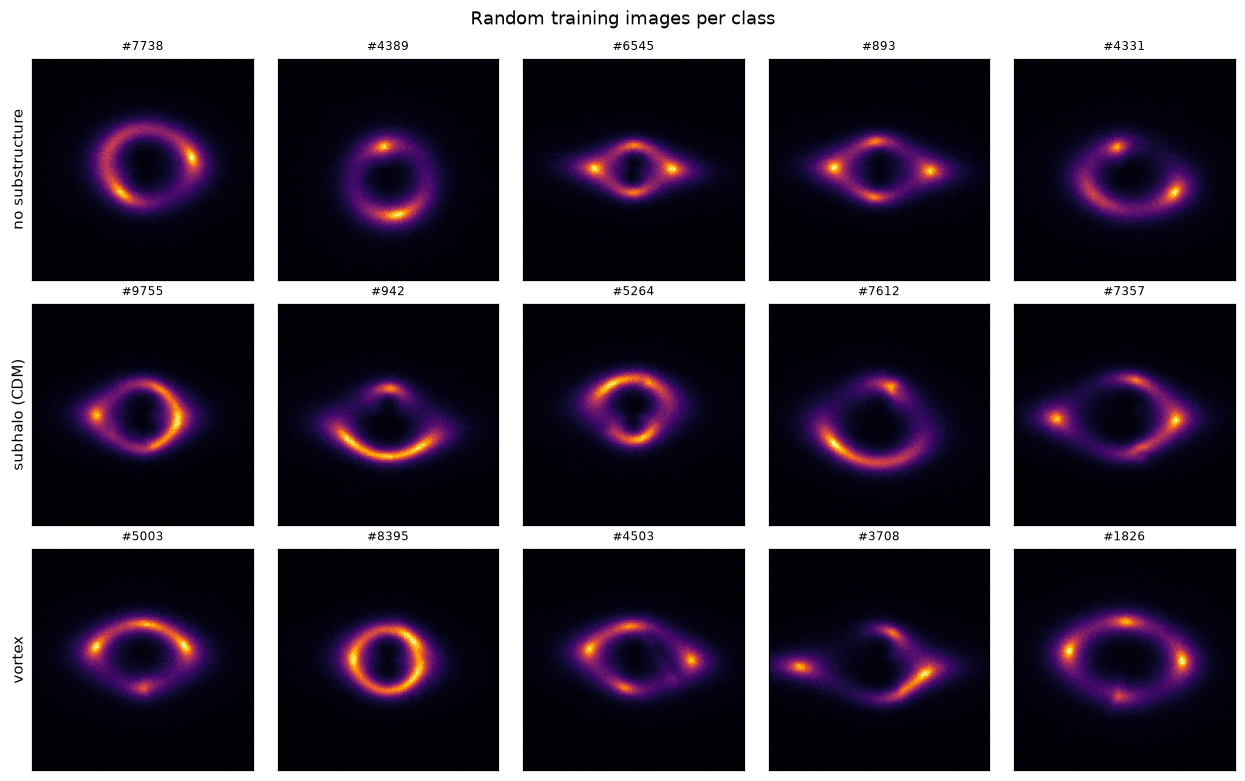

In [6]:
n_show = 5
fig, axes = plt.subplots(3, n_show, figsize=(2.3 * n_show, 7.2))
for r, cls in enumerate(CLASSES):
    idx = rng.choice(np.flatnonzero(y_trainfull == r), n_show, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(X_trainfull[i, 0], cmap="inferno", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"#{train_paths[i].stem}", fontsize=8)
    axes[r, 0].set_ylabel(NAMES[cls], fontsize=10)
fig.suptitle("Random training images per class")
fig.tight_layout()
fig.savefig(FIG / "01_examples.png", bbox_inches="tight")
plt.show()

## 6. Mean image per class, and how each class differs from "no substructure"
If the classes differed in something global (size of the ring, position, brightness), it would show up here. The difference maps
use a symmetric red/blue scale: red = brighter than the no-substructure mean, blue = darker.

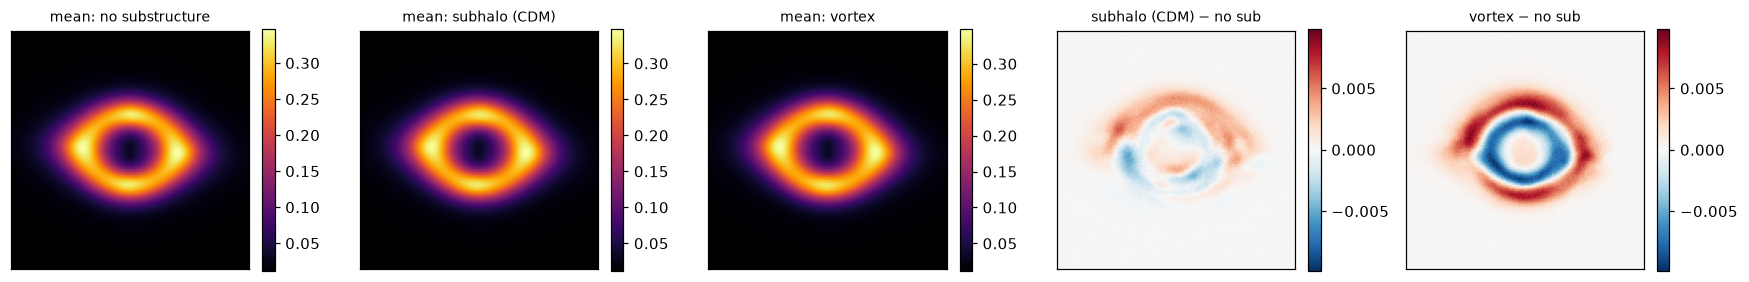

sphere: largest |difference| from 'no' mean = 0.0063 (pixel values range 0–1)
vort  : largest |difference| from 'no' mean = 0.0099 (pixel values range 0–1)


In [7]:
means = {cls: X_trainfull[y_trainfull == i, 0].mean(0) for i, cls in enumerate(CLASSES)}
diffs = {cls: means[cls] - means["no"] for cls in ["sphere", "vort"]}
lim = max(np.abs(d).max() for d in diffs.values())

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, cls in zip(axes[:3], CLASSES):
    im = ax.imshow(means[cls], cmap="inferno"); ax.set_title(f"mean: {NAMES[cls]}", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax, cls in zip(axes[3:], ["sphere", "vort"]):
    im = ax.imshow(diffs[cls], cmap="RdBu_r", vmin=-lim, vmax=lim); ax.set_title(f"{NAMES[cls]} − no sub", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "01_mean_and_difference.png", bbox_inches="tight"); plt.show()

for cls in ["sphere", "vort"]:
    print(f"{cls:6s}: largest |difference| from 'no' mean = {np.abs(diffs[cls]).max():.4f} (pixel values range 0–1)")

## 7. Distributions per class
Histograms of simple per-image numbers (overall brightness, contrast, how much of the image is lit), and of the raw pixel values.
If the three curves sit on top of each other, those simple numbers cannot separate the classes.

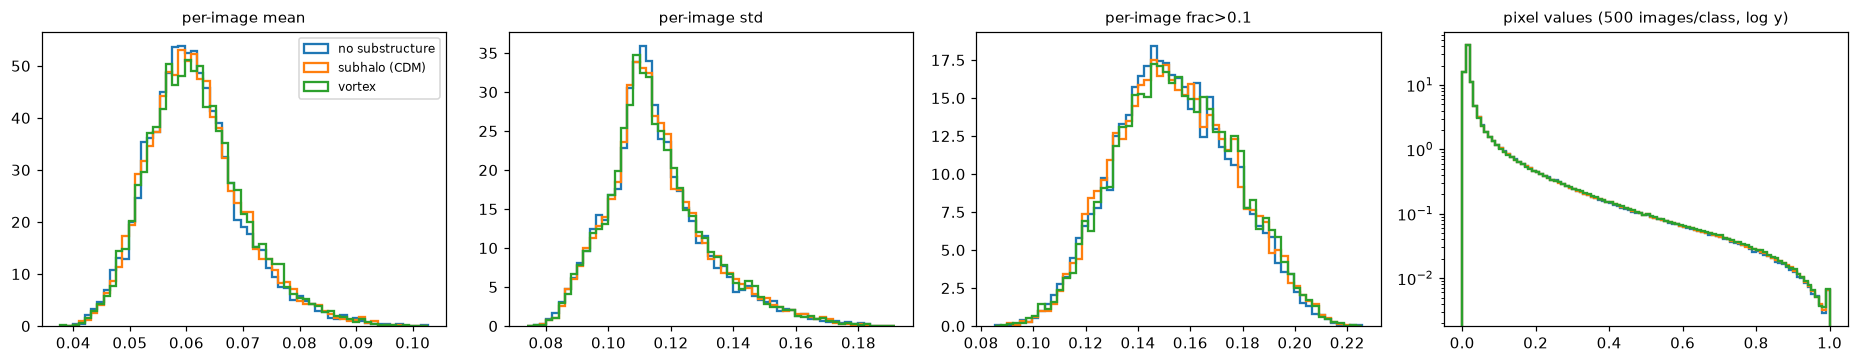

In [8]:
tr = stats[stats["split"] == "train/"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, col in zip(axes[:3], ["mean", "std", "frac>0.1"]):
    bins = np.linspace(tr[col].min(), tr[col].max(), 60)
    for cls in CLASSES:
        ax.hist(tr.loc[tr["class"] == cls, col], bins=bins, histtype="step", lw=1.5, density=True, label=NAMES[cls])
    ax.set_title(f"per-image {col}", fontsize=10)
axes[0].legend(fontsize=8)

sample = {cls: X_trainfull[rng.choice(np.flatnonzero(y_trainfull == i), 500, replace=False)].ravel()
          for i, cls in enumerate(CLASSES)}
for cls in CLASSES:
    axes[3].hist(sample[cls], bins=100, range=(0, 1), histtype="step", lw=1.5, density=True, log=True, label=NAMES[cls])
axes[3].set_title("pixel values (500 images/class, log y)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "01_distributions.png", bbox_inches="tight"); plt.show()

## 8. Shortcut check: can simple numbers alone classify the images?
A logistic regression on 8 per-image numbers (no pixels, no shapes). If its AUC is close to 0.5, there is no easy shortcut and a
CNN has to learn the actual morphology of the arcs. This also gives a floor that the CNN must clearly beat.
It is scored with 5-fold cross-validation **inside `train/`**, so the held-out `val/` set stays untouched.

In [9]:
def simple_features(X):
    flat = X.reshape(len(X), -1)
    q = np.percentile(flat, [50, 90, 99], axis=1).T
    return np.column_stack([flat.mean(1), flat.std(1), q, (flat > 0.1).mean(1), (flat > 0.5).mean(1), flat.max(1)])

F_trainfull = simple_features(X_trainfull)
shortcut = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
proba = cross_val_predict(shortcut, F_trainfull, y_trainfull, cv=cv, method="predict_proba")
print("5-fold CV macro one-vs-rest AUC (8 simple numbers only): %.3f"
      % roc_auc_score(y_trainfull, proba, multi_class="ovr", average="macro"))
for i, cls in enumerate(CLASSES):
    print(f"  {NAMES[cls]:16s} vs rest: AUC {roc_auc_score(y_trainfull == i, proba[:, i]):.3f}")

5-fold CV macro one-vs-rest AUC (8 simple numbers only): 0.507
  no substructure  vs rest: AUC 0.510
  subhalo (CDM)    vs rest: AUC 0.498
  vortex           vs rest: AUC 0.513


## 9. Duplicate / leakage check
If the same image appears in both `train/` and `val/`, the final score would be inflated. Each image's bytes are hashed and compared.

In [10]:
def hashes(X):
    return np.array([hashlib.sha1(img.tobytes()).hexdigest() for img in X])

h_trainfull, h_test = hashes(X_trainfull), hashes(X_test)
print("duplicates inside train/:", len(h_trainfull) - len(set(h_trainfull)))
print("duplicates inside val/  :", len(h_test) - len(set(h_test)))
print("images found in both    :", len(set(h_trainfull) & set(h_test)))

duplicates inside train/: 0
duplicates inside val/  : 0
images found in both    : 0


## 10. The 90:10 split of `train/`
Stratified, so each part keeps 1/3 of every class. The indices are saved, so every training notebook uses exactly this split.

In [11]:
idx_train, idx_valid = train_test_split(np.arange(len(y_trainfull)), test_size=0.10, stratify=y_trainfull, random_state=SEED)
idx_train, idx_valid = np.sort(idx_train), np.sort(idx_valid)
assert len(np.intersect1d(idx_train, idx_valid)) == 0 and len(idx_train) + len(idx_valid) == len(y_trainfull)

split_counts = pd.DataFrame({
    "train (90 %)": np.bincount(y_trainfull[idx_train], minlength=3),
    "valid (10 %)": np.bincount(y_trainfull[idx_valid], minlength=3),
    "test = val/":  np.bincount(y_test, minlength=3),
}, index=[NAMES[c] for c in CLASSES])
split_counts.loc["total"] = split_counts.sum()
display(split_counts)

,train (90 %),valid (10 %),test = val/
no substructure,9000,1000,2500
subhalo (CDM),9000,1000,2500
vortex,9000,1000,2500
total,27000,3000,7500


## 11. Save everything for the training notebooks
One array per split instead of 37,500 small files: loading becomes a single read (or a memory map).

In [12]:
np.save(PROC / "trainfull_X.npy", X_trainfull); np.save(PROC / "trainfull_y.npy", y_trainfull)
np.save(PROC / "test_X.npy", X_test);           np.save(PROC / "test_y.npy", y_test)
meta = {
    "classes": CLASSES, "class_names": NAMES, "seed": SEED,
    "train_idx": idx_train.tolist(), "valid_idx": idx_valid.tolist(),
    "trainfull_files": [str(p.relative_to(RAW)) for p in train_paths],
    "test_files": [str(p.relative_to(RAW)) for p in test_paths],
    "pixel_mean_trainfull": float(X_trainfull[idx_train].mean(dtype=np.float64)),
    "pixel_std_trainfull":  float(X_trainfull[idx_train].std(dtype=np.float64)),
    "note": "test = provided val/ folder; normalisation stats come from the 90 % train part only",
}
(PROC / "split.json").write_text(json.dumps(meta))

# check: reload and compare
Xr = np.load(PROC / "trainfull_X.npy", mmap_mode="r"); Tr = np.load(PROC / "test_X.npy", mmap_mode="r")
assert Xr.shape == X_trainfull.shape and np.array_equal(Xr[[0, 12345, -1]], X_trainfull[[0, 12345, -1]])
assert np.array_equal(Tr[[0, -1]], X_test[[0, -1]])
assert np.array_equal(np.load(PROC / "trainfull_y.npy"), y_trainfull) and np.array_equal(np.load(PROC / "test_y.npy"), y_test)
for f in sorted(PROC.iterdir()):
    print(f"{f.name:18s} {f.stat().st_size / 1e6:8.1f} MB")
print("normalisation (train part only): mean %.5f  std %.5f" % (meta["pixel_mean_trainfull"], meta["pixel_std_trainfull"]))

split.json              1.0 MB
test_X.npy            675.0 MB
test_y.npy              0.1 MB
trainfull_X.npy      2700.0 MB
trainfull_y.npy         0.2 MB
normalisation (train part only): mean 0.06169  std 0.11730


## 12. What I found

1. **The data is clean.** 30,000 training and 7,500 held-out images, exactly 1/3 per class. Every file has shape (1, 150, 150) and no
   NaN/Inf values. No image appears twice, and none is shared between `train/` and `val/`. Storing the images as float32 changes values
   by less than 3e-8.
2. **Every image is min-max normalised on its own** (min = 0 and max = 1 in 100 % of images). Absolute brightness therefore carries no
   information; only the *shape and distribution* of the light does.
3. **The classes look almost the same at a glance.** All three show an Einstein ring or arcs around a dark centre. The class mean images
   differ by at most about 0.01 on a 0–1 scale. The vortex mean has a faint ring pattern (red outside, blue inside the ring), so vortex
   rings are on average very slightly larger or wider. The subhalo difference is weaker and patchy, which fits clumps at random positions.
4. **There is no easy shortcut.** Per-image brightness, contrast and lit-area histograms overlap almost perfectly. A logistic regression
   on 8 such numbers reaches a cross-validated macro AUC of only about 0.5, i.e. chance. A good score has to come from learning the small,
   local distortions of the arcs.

**Decisions for the training notebook (`02_baseline_resnet.ipynb`):**
- Use the saved split: train = 27,000 images (`train_idx`), valid = 3,000 (`valid_idx`, for choosing the epoch), and test = `val/`
  (7,500, used once at the end).
- Standardise inputs with the train-part mean and std stored in `split.json`.
- Augment only with transformations that do not change the physics: horizontal/vertical flips and 90° rotations. Lensing has no
  preferred orientation, and the 150×150 grid is preserved exactly. Avoid blur, colour jitter and random crops: they could erase or fake
  the faint substructure signal.
- Because the signal is small and local, keep full resolution (no downsizing to 64×64) and compare a CNN that keeps detail early
  (ResNet-18 with a 3×3 first conv and no max-pool) against the standard one.